# Lecture 25 - joining tables: `merge`
### EES 3350/5350 · Python in Earth Science · Wednesday, November 4, 2026 

Last week you **stacked** tables wtih `pd.concat`: same columns, more rows. 

Today's problem is different. The information you need is split across **different tables that describe the same things**: 
- one file has eacy river gauge's daily discharge
- another file has **where** each gauge is and **how much land** drains to it
- a third has the measurements a field crew made **by hand**.

To answer a question, you have to **line those tables up**, row by row, using something they share. That operation is called a **join**, and in pandas it's `pd.merge`. 

Joins are everywhere in Earth science: sample IDs <--> lab chemistry, station IDs <--> coordinates, rock codes <--> rock names, dates <--> a climate index.

**Learning objectives**
- explain the difference between **stacking** (`pd.concat`) and **joining** (`pd.merge`)
- join two tables on a shared **key** column with `pd.merge(..., on=...)`
- fix the "int vs text key" error and fix it with `dtype=`
- choose `how="inner"`, `"left"`, `"right"`, or `"outer"`, and use `indicator=True` to see which rows matched
- use a **date** as just another key to put several gauges side by side
- make figures that only become possible **after** a join


---
## Part 0 : set up

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data = "../../course-materials/week11/"
folder = Path(data) / "usgs"

We'll give each gauge its own color to use it in every figure today, so the same river always looks the same. Feel free to change these to your favorite colors. The one's I've chosen are three colors that are easy to tell apart, including for people with the most common kinds of color blindness.

In [3]:
colors = {"Cumberland": "#0072B2", 
          "Harpeth": "#E69F00", 
          "Mill Creek": "#009E73"}

## Part 0.5 : some background

![rainfall totals March 2021](../figures/nashville_march_2021_floods.jpg)
<p><span style="font-size:0.85em;color:#6b7a8d;"><em>Source: National Weather Service. Find <a href="https://www.weather.gov/ohx/20210327">the NWS report here </a></em></span>

On **March 27-28, 2021**, about 7 inches of rain fell on Nashville in two days (7.01 inches at Nashville International Airport). Small creeks rose within hours. The National Weather Service called it the worst flooding in Middle Tennessee since May 2010: Mill Creek near Woodbine and the Harpeth River near Kingston Spring both reached their **second-highest** levels on record, behind only May 2010. Seven people died.

We have files from three USGS stream gauges for February-April 2021:
|**gauge**|**what it is**|
|:--|:--|
|Cumberland River at Nashville (03431500)| the big river, downtown|
|Harpeth River near Kingston Springs (03434500)| a mid-sized river west of Nashville|
|Mill Creek at Thompson Lane, near Woodbine (03431060)| a creek in southeast Nashville|

For each gauge there are three files, exactly as they come from the USGS website:
|**file ending**|**What's init**|
|:--|:--|
|`_daily.csv`| the **daily mean discharge**: one number per day |
|`_site.csv` | information **about the gauge**: its name, location and drainage area|
|`_field.csv`| discharge measured **by hand** by a USGS crew, on a few days|

<span style="font-size:0.85em;color:#6b7a8d;"><em>Data: U.S. Geological Survey, 2026, USGS Water Data for the Nation, daily mean discharge (parameter 00060), field measurements, and monitoring-location metadata for sites 03431500, 03434500, and 03431060, Feb. 1–Apr. 30, 2021, https://waterdata.usgs.gov, accessed Nov. 3, 2026. Flood details: National Weather Service Nashville, "March 27–28, 2021 Flash Flooding," weather.gov/ohx/20210327.</em></span>


---
## Part 1 : read and stack the daily files (review)

This is the Lecture 24 pattern: list the files, read each the same way, stack them.

In [4]:
!head -3 {data}usgs/millcreek_daily.csv

x,y,time_series_id,monitoring_location_id,parameter_code,statistic_id,time,value,unit_of_measure,approval_status,qualifier,last_modified
-86.7190478385063,36.1175747584019,802f977f75ef46c9802b5f66319f7148,USGS-03431060,00060,00003,2021-04-30,219,ft^3/s,Approved,,2025-03-11 19:32:59.546058+00:00
-86.7190478385063,36.1175747584019,802f977f75ef46c9802b5f66319f7148,USGS-03431060,00060,00003,2021-04-29,217,ft^3/s,Approved,,2025-03-11 19:32:59.546058+00:00


Lots of columns, but we only need three:

|**column**|**what it means**|
|:--|:--|
|`monitoring_location_id`|which gauge (`USGS-` + the site number)|
|`time`|the date|
|`value`|the daily mean discharge, in ft³/s|

Notice the first date is **April 30**: USGS gives you the newest day first.

In [5]:
pieces = []

for path in sorted(folder.glob("*_daily.csv")):
    df = pd.read_csv(path)
    pieces.append(df)

daily = pd.concat(pieces, ignore_index=True)
daily = daily[["monitoring_location_id", "time", "value"]]

print(daily.shape)
daily.head

(267, 3)


<bound method NDFrame.head of     monitoring_location_id        time    value
0            USGS-03431500  2021-04-30  22800.0
1            USGS-03431500  2021-04-29  21100.0
2            USGS-03431500  2021-04-28  13800.0
3            USGS-03431500  2021-04-27  19000.0
4            USGS-03431500  2021-04-26  20500.0
..                     ...         ...      ...
262          USGS-03431060  2021-02-05     92.5
263          USGS-03431060  2021-02-04     82.2
264          USGS-03431060  2021-02-03     87.1
265          USGS-03431060  2021-02-02     98.4
266          USGS-03431060  2021-02-01    114.0

[267 rows x 3 columns]>

#### **What just happened?** 
`folder.glob("*_daily.csv")` found the three daily files. The loop read each one and put it in the list `pieces`. `pd.concat` stacked the three tables into one: 3 gauges × 89 days = **267 rows**. Then we kept only the three columns we need.

These files already have a column saying which gauge each row came from, so we didn't need to add one inside a loop (like we did in class on Monday).

Two clean-up steps: 
1. turn `time` into real dates, so pandas knows March comes after February
2. sort oldest-first. `.sort-values()` can take a **list** of columns: it sorts by the first, and breaks ties with the second (by date).

In [6]:
daily["time"] = pd.to_datetime(daily["time"])
daily = daily.sort_values(["monitoring_location_id", "time"], ignore_index=True)

daily.head

<bound method NDFrame.head of     monitoring_location_id       time   value
0            USGS-03431060 2021-02-01   114.0
1            USGS-03431060 2021-02-02    98.4
2            USGS-03431060 2021-02-03    87.1
3            USGS-03431060 2021-02-04    82.2
4            USGS-03431060 2021-02-05    92.5
..                     ...        ...     ...
262          USGS-03434500 2021-04-26   682.0
263          USGS-03434500 2021-04-27   622.0
264          USGS-03434500 2021-04-28   662.0
265          USGS-03434500 2021-04-29  1140.0
266          USGS-03434500 2021-04-30  1260.0

[267 rows x 3 columns]>

#### Now let's plot it:

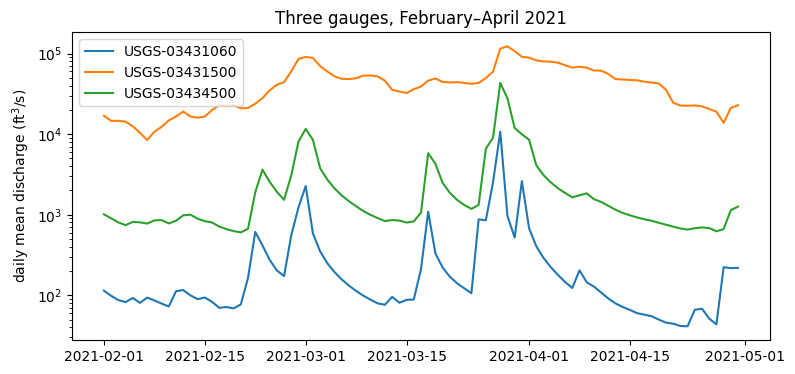

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))

for gauge in daily["monitoring_location_id"].unique():
    one = daily[daily["monitoring_location_id"] == gauge]
    ax.plot(one["time"], one["value"], label=gauge)

ax.set_yscale("log")
ax.set_ylabel("daily mean discharge (ft$^3$/s)")
ax.set_title("Three gauges, February–April 2021")
ax.legend();

A log scale lets all three fit on one figure: the Cumberland carries about 100 times more water than Mill Creek on an ordinary day. All three jump at the end of March.

<div class="alert alert-warning">

### Question 1:

Which line is the Cumberland? Which is Mill Creek? How big is each river's watershed? Can you answer any of these from `daily` alone?

</div>

> your answer here

<details>
<summary style="color:green;"><strong>Answer</strong></summary>

Not from `daily` alone. It only has the codes `USGS-03431060`, `USGS-03431500`, and `USGS-03434500`. The names and the watershed sizes are in a **different table**, the `_site.csv` files. To use them, we have to join the two tables. That's Part 2.

</details>

---
## Part 2 : joining two tables on a key

### Stacking vs. joining
|**`pd.concat` (Lecture 23)**|**`pd.merge` (today)**
|:--|:--|
|tables with the **same columns**| tables with **different columns** about the **same things**|
|puts one table **under** another| puts matching rows **side by side**|
|rows lined up by **position**| rows lined up by the value in a **key** column|
|result has **more rows**| result has **more columns**|

The **key** is the column both tables share, like a gauge ID or a sample number. `merg` finds rows with the **same key** in both tables and glues them together.

### Step 1 : a table with one row per gauge

`groupby` gives each gauge's peak an dmean, one step at a time:

In [8]:
grouped = daily.groupby("monitoring_location_id")

peak = grouped["value"].max()
mean = grouped["value"].mean().round(0)

stats = pd.DataFrame({"peak_cfs": peak, "mean_cfs": mean})
stats

,peak_cfs,mean_cfs
monitoring_location_id,,
USGS-03431060,10700.0,402.0
USGS-03431500,123000.0,43561.0
USGS-03434500,43200.0,2879.0


The gauge IDs are in **bold** on the left: `groupby` put them in the **index**, not in a column. To join on them, we need them as an ordinary column. `.reset_index()` does exactly that.

In [9]:
stats = stats.reset_index()
stats

,monitoring_location_id,peak_cfs,mean_cfs
0,USGS-03431060,10700.0,402.0
1,USGS-03431500,123000.0,43561.0
2,USGS-03434500,43200.0,2879.0


#### **What just happened?** 
The gauge IDs moved out of the index and into a column named `monitoring_location_id`. The row labels are back to plain 0, 1, 2.

### Step 2 : a table about the agues themselves

The three `_site.csv` files hold 44 columns of information about each gauge. Stack them and keep the few we need:

In [10]:
pieces = []

for path in sorted(folder.glob("*_site.csv")):
    pieces.append(pd.read_csv(path))

sites = pd.concat(pieces, ignore_index=True)
sites = sites[["id", "monitoring_location_number", "monitoring_location_name", "drainage_area"]]

sites

,id,monitoring_location_number,monitoring_location_name,drainage_area
0,USGS-03431500,3431500,"CUMBERLAND RIVER AT NASHVILLE, TN",12856.0
1,USGS-03434500,3434500,"HARPETH RIVER NEAR KINGSTON SPRINGS, TN",683.0
2,USGS-03431060,3431060,"MILL CREEK AT THOMPSON LANE, NEAR WOODBINE, TN",93.4


`drainage_area` is in **square miles** (the USGS standard, unfortunately): the area of land whose rain ends up flowing past the gauge.

### Step 3 : make the key columns match

Both tables describe the same three gauges, but the gauge ID column has a different name. We can rename it so that two match:
|**table**|**ID column**|
|:--|:--|
|`stats`|`monitoring_location_id`|
|`sites`|`id`|

In [11]:
sites = sites.rename(columns={"id":"monitoring_location_id"})
sites

,monitoring_location_id,monitoring_location_number,monitoring_location_name,drainage_area
0,USGS-03431500,3431500,"CUMBERLAND RIVER AT NASHVILLE, TN",12856.0
1,USGS-03434500,3434500,"HARPETH RIVER NEAR KINGSTON SPRINGS, TN",683.0
2,USGS-03431060,3431060,"MILL CREEK AT THOMPSON LANE, NEAR WOODBINE, TN",93.4


In [12]:
sites.head()

,monitoring_location_id,monitoring_location_number,monitoring_location_name,drainage_area
0,USGS-03431500,3431500,"CUMBERLAND RIVER AT NASHVILLE, TN",12856.0
1,USGS-03434500,3434500,"HARPETH RIVER NEAR KINGSTON SPRINGS, TN",683.0
2,USGS-03431060,3431060,"MILL CREEK AT THOMPSON LANE, NEAR WOODBINE, TN",93.4


### Step 4 : merge!

`pd.merge(left, right, on="KEY"`
- `left` is the table you write **first** and `right` is the table you write **second**
- `on=` names the **key**: the colum whose values must match.

In [13]:
gauges = pd.merge(stats, sites, on="monitoring_location_id")

gauges

,monitoring_location_id,peak_cfs,mean_cfs,monitoring_location_number,monitoring_location_name,drainage_area
0,USGS-03431060,10700.0,402.0,3431060,"MILL CREEK AT THOMPSON LANE, NEAR WOODBINE, TN",93.4
1,USGS-03431500,123000.0,43561.0,3431500,"CUMBERLAND RIVER AT NASHVILLE, TN",12856.0
2,USGS-03434500,43200.0,2879.0,3434500,"HARPETH RIVER NEAR KINGSTON SPRINGS, TN",683.0


### What just happened?

For each row of `stats`, pandas found the row of `sites` with the **same** `monitoring_location_id` and glued the two together. Now each gauge's peak, mean, name, and drainage area re in **one** row.

The rows of `stats` and `sites` were **not** in the same order. But that didn't matter, because `merge` matches by **value**, not by position.

|**`stats` row**|**looks for this key in `sites`**|**result row**|
|:--|:--|:--|
|`USGS-03431060`, peak 10,700| row 2, `USGS-03431060`, Mill Creek, 93.4 sq mi | Mill Creek with its peak **and** its area|
|`USGS-03431500`, peak 123,00| row 0, `USGS-03431500`, Cumberland, 12, 856 sq mi| Cumberland with both|
|`USGS-03434500`, peak 43,200| row 1, `USGS-03434500`, Harpeth, 683 sq mi | Harpeth with both|

If you had used `pd.concat` here, it would have put the tables next to each other by **position**, and Mill Creek's peak would have ended up next to the Cumberland's drainage area.

### A common error: when the key isn't the same type
Long station names make bad plot labels. Here is a small table of short names. We typed the site numbers the way USGS writes them, **with** the leading zero:

In [14]:
short = pd.DataFrame({
    "site_no": ["03431500", "03434500", "03431060"],
    "short_name":["Cumberland", "Harpeth", "Mill Creek"],
})

short

,site_no,short_name
0,03431500,Cumberland
1,03434500,Harpeth
2,03431060,Mill Creek


This time key columns have **different names**: `monitoring_location_number` in `gauges` and `site_no` in `short`. Instead of renaming, you can tell merge which column to use on each side:
- `left_on=` : the key column in the **left** table
- `right_on=` : the key column in the **right** table

In [15]:
pd.merge(gauges, short, left_on="monitoring_location_number", right_on="site_no")

ValueError: You are trying to merge on int64 and str columns for key 'monitoring_location_number'. If you wish to proceed you should use pd.concat

#### Oh no!

Let's read the error: it says one key column is **int** (a whole number) and the other is **str** (text).

Look back at `sites`: `monitoring_location_number` shows `3431500`, **no leading zero**. The file says `03431500`, but `read_csv` saw only digits and decided it was a number, and a number can't start with 0.

#### The problem: `03431500` is not a quantity. It's a **name** that happens to use digits.
- like a ZIP code or a phone number

So it should be text. We can tell `read_csv` that it's text with `dtype=` (a dictionary of `"column" : type"`):

In [16]:
pieces = []

for path in sorted(folder.glob("*_site.csv")):
    pieces.append(pd.read_csv(path, dtype={"monitoring_location_number": str}))

sites = pd.concat(pieces, ignore_index=True)
sites = sites[["id", "monitoring_location_number", "monitoring_location_name", "drainage_area"]]
sites = sites.rename(columns={"id": "monitoring_location_id"})

sites["monitoring_location_number"]

0    03431500
1    03434500
2    03431060
Name: monitoring_location_number, dtype: str

The leading zeros are back...

But we can redo both merges:

In [17]:
gauges = pd.merge(stats, sites, on="monitoring_location_id")
gauges = pd.merge(gauges, short, left_on="monitoring_location_number", right_on="site_no")

gauges

,monitoring_location_id,peak_cfs,mean_cfs,monitoring_location_number,monitoring_location_name,drainage_area,site_no,short_name
0,USGS-03431060,10700.0,402.0,03431060,"MILL CREEK AT THOMPSON LANE, NEAR WOODBINE, TN",93.4,03431060,Mill Creek
1,USGS-03431500,123000.0,43561.0,03431500,"CUMBERLAND RIVER AT NASHVILLE, TN",12856.0,03431500,Cumberland
2,USGS-03434500,43200.0,2879.0,03434500,"HARPETH RIVER NEAR KINGSTON SPRINGS, TN",683.0,03434500,Harpeth


<div class="alert alert-danger">

**Common Error**: ID codes with leading zeros (USGS site numbers, ZIP codes, sample IDz like `007`) silently lose their zeros when read as numbers. Even when nothing crashes, a key `3431500` will **never** match `03431500`. Read ID columns as text: `pd.read_csv(path, dtype={"COLUMN": str})`.
    
</div>

### The same figure, now readable

`daily` has 267 rows, and `gauges` has 3. Merging them gives **every** daily row its gauge's short name: each gauge's name gets copied into all 89 of its days:

In [18]:
names = gauges[["monitoring_location_id", "short_name"]]

daily = pd.merge(daily, names, on="monitoring_location_id")

print(daily.shape)
daily.head(3)

(267, 4)


,monitoring_location_id,time,value,short_name
0,USGS-03431060,2021-02-01,114.0,Mill Creek
1,USGS-03431060,2021-02-02,98.4,Mill Creek
2,USGS-03431060,2021-02-03,87.1,Mill Creek


#### **What just happened?** 
Still 267 rows (good: no days lost or added), but now there's a `short_name` column. Each name from the 3-row table was copied onto all of that gauge's days.


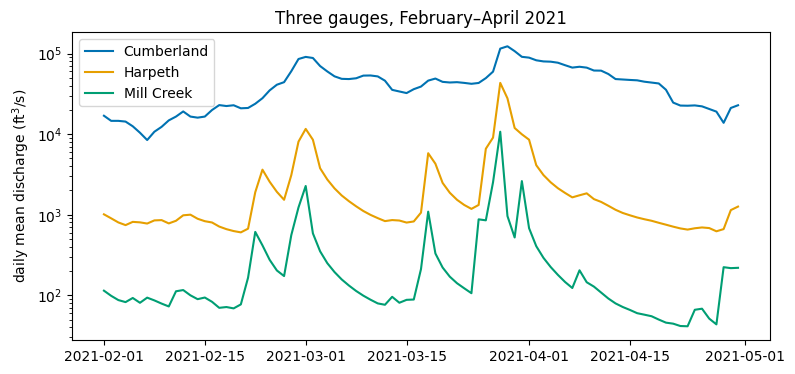

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))

for name in ["Cumberland", "Harpeth", "Mill Creek"]:
    one = daily[daily["short_name"] == name]
    ax.plot(one["time"], one["value"], label=name, color=colors[name])

ax.set_yscale("log")
ax.set_ylabel("daily mean discharge (ft$^3$/s)")
ax.set_title("Three gauges, February–April 2021")
ax.legend();

<div class="alert alert-info">

### Exercise 1 : who flooded hardest?

`gauges` now has each gauge's peak, mean, and drainage area in one row. Replace each `___` and run the cell.

1. `peak_per_sqmi`: the peak discharge divided by the drainage area (ft$^3$/s per square mile).
2. `peak_over_mean`: how many times its own February-April mean flow was each gauge's peak?
3. a smaller table, sorted from the smallest watershed to the biggest.
</div>

In [20]:
gauges["peak_per_sqmi"] = gauges["peak_cfs"] / gauges["drainage_area"]
gauges["peak_over_mean"] = gauges["peak_cfs"] / gauges["mean_cfs"]

summary = gauges[["short_name", "drainage_area", "peak_per_sqmi", "peak_over_mean"]]
summary = summary.sort_values("drainage_area")

summary.round(1)

,short_name,drainage_area,peak_per_sqmi,peak_over_mean
0,Mill Creek,93.4,114.6,26.6
2,Harpeth,683.0,63.3,15.0
1,Cumberland,12856.0,9.6,2.8


susannah: look into reverse sortingm

Once your table works, run this cell to see your result as a figure:

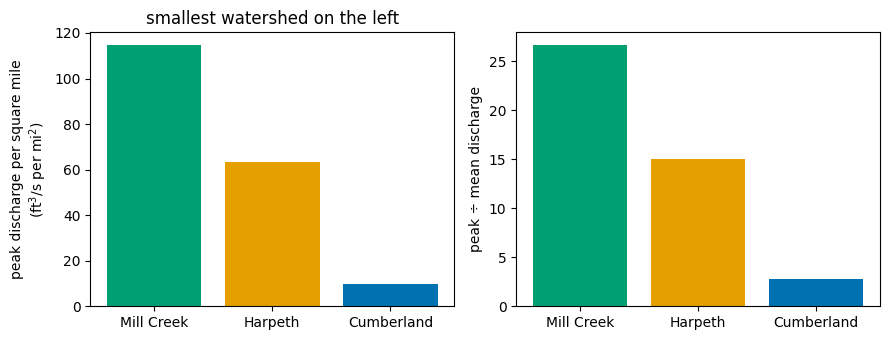

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

for name in summary["short_name"]:
    one = summary[summary["short_name"] == name]
    axes[0].bar(one["short_name"], one["peak_per_sqmi"], color=colors[name])
    axes[1].bar(one["short_name"], one["peak_over_mean"], color=colors[name])

axes[0].set_ylabel("peak discharge per square mile\n(ft$^3$/s per mi$^2$)")
axes[1].set_ylabel("peak ÷ mean discharge")
axes[0].set_title("smallest watershed on the left")
fig.tight_layout();

<div class="alert alert-warning">

### Question 2:
Mill Creek's peak (10,700 ft³/s) was less than a tenth of the Cumberland's (123,000 ft³/s). So did the Cumberland flood hardest? What do the two bar charts say? Why might a **small** watershed produce more water per square mile than a big one?

</div>

> your answer here

<details>
<summary style="color:green;"><strong>Answer</strong></summary>

The **smaller** the watershed, the harder it flooded. Mill Creek produced about 115 ft³/s per square mile, about **12 times** the Cumberland's 10, and its peak was about 27 times its own average flow (the Cumberland's was about 3).

Rain falling on a small watershed reaches the gauge all at once. A big watershed collects water from places that got less rain, and that water takes days to arrive. The Cumberland is also **regulated**: dams upstream (Old Hickory, J. Percy Priest) hold water back.

Raw discharge alone (123,000 vs. 10,700) tells the **opposite** story. Only joining on drainage area showed what really happened.

</details>

---
## Part 3 : two keys, and columns with the same name

A stream gauge doesn't measure discharge directly. 

![rainfall totals March 2021](../figures/gage_graphic.JPG)
<p><span style="font-size:0.85em;color:#6b7a8d;"><em>Sources/Usage: Public Domain. </em></span>

It measures the water's **height**, and turns that into discharge using a formula. To check the formula, USGS crews visit each gauge and measure the discharge **by hand**, measuring how fast the water moves across the whole channel.

In [22]:
pieces = []

for path in sorted(folder.glob("*_field.csv")):
    pieces.append(pd.read_csv(path))

field = pd.concat(pieces, ignore_index=True)
field = field[["monitoring_location_id", "time", "time_of_day", "value"]]
field["time"] = pd.to_datetime(field["time"])

field

,monitoring_location_id,time,time_of_day,value
0,USGS-03431500,2021-04-12,16:45:38+00:00,55100
1,USGS-03431500,2021-02-08,16:51:21+00:00,12800
2,USGS-03434500,2021-03-28,22:01:21+00:00,40200
3,USGS-03434500,2021-03-28,23:05:07+00:00,38100
4,USGS-03434500,2021-02-04,17:50:49+00:00,741
5,USGS-03431060,2021-03-31,14:09:54+00:00,5440
6,USGS-03431060,2021-03-31,14:36:44+00:00,4680
7,USGS-03431060,2021-02-25,16:04:40+00:00,211


Okay, so we have eight measurements made on six days. Notice that crews measured **twice** on some days: the Harpeth on March 28 (right at the flood peak) and Mill Creek on March 31.

#### How does each hand measurement compare to that day's **daily mean**? 
To line them up, a row has to match on the gauge **and** on the date. Give `on=` a **list** of both:

In [23]:
compare = pd.merge(field, daily, on=["monitoring_location_id", "time"])

compare

,monitoring_location_id,time,time_of_day,value_x,value_y,short_name
0,USGS-03431500,2021-04-12,16:45:38+00:00,55100,55700.0,Cumberland
1,USGS-03431500,2021-02-08,16:51:21+00:00,12800,10700.0,Cumberland
2,USGS-03434500,2021-03-28,22:01:21+00:00,40200,43200.0,Harpeth
3,USGS-03434500,2021-03-28,23:05:07+00:00,38100,43200.0,Harpeth
4,USGS-03434500,2021-02-04,17:50:49+00:00,741,742.0,Harpeth
5,USGS-03431060,2021-03-31,14:09:54+00:00,5440,2610.0,Mill Creek
6,USGS-03431060,2021-03-31,14:36:44+00:00,4680,2610.0,Mill Creek
7,USGS-03431060,2021-02-25,16:04:40+00:00,211,203.0,Mill Creek


Both tables had a column called `value`, so pandas renamed them:
- `value_x`: from the left table (`field`, the hand measurement)
- `value_y`: from the right table (`daily`, the daily mean)

That works, but in a week, no one will remember which is which. 

`suffixes=` lets you choose the endings, left first:

In [24]:
compare = pd.merge(field, daily, on=["monitoring_location_id", "time"], suffixes=("_measured", "_daily"))

compare

,monitoring_location_id,time,time_of_day,value_measured,value_daily,short_name
0,USGS-03431500,2021-04-12,16:45:38+00:00,55100,55700.0,Cumberland
1,USGS-03431500,2021-02-08,16:51:21+00:00,12800,10700.0,Cumberland
2,USGS-03434500,2021-03-28,22:01:21+00:00,40200,43200.0,Harpeth
3,USGS-03434500,2021-03-28,23:05:07+00:00,38100,43200.0,Harpeth
4,USGS-03434500,2021-02-04,17:50:49+00:00,741,742.0,Harpeth
5,USGS-03431060,2021-03-31,14:09:54+00:00,5440,2610.0,Mill Creek
6,USGS-03431060,2021-03-31,14:36:44+00:00,4680,2610.0,Mill Creek
7,USGS-03431060,2021-02-25,16:04:40+00:00,211,203.0,Mill Creek


If the hand measurements and the daily mean were always the same, every point would fall on the dashed **1:1 line**.

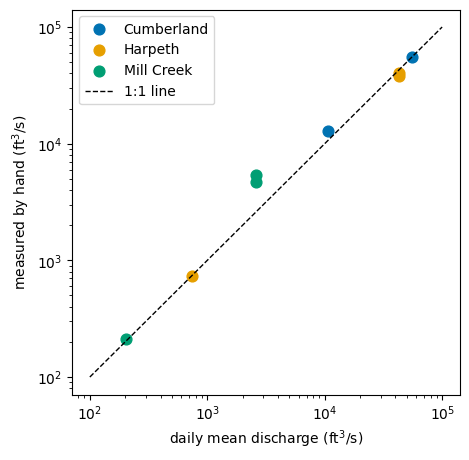

In [25]:
fig, ax = plt.subplots(figsize=(5, 5))

for name in ["Cumberland", "Harpeth", "Mill Creek"]:
    one = compare[compare["short_name"] == name]
    ax.scatter(one["value_daily"], one["value_measured"], s=60, label=name, color=colors[name])

ax.plot([100, 100000], [100, 100000], "k--", linewidth=1, label="1:1 line")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("daily mean discharge (ft$^3$/s)")
ax.set_ylabel("measured by hand (ft$^3$/s)")
ax.legend();

#### What just happened?

Most points sit right on the line: on most days, one hand measurement is close to the average for the whole day. The two Mill Creek points from march 31 sit well **above** the line. You'll find out why in a bit...

---
## Part 4 : rows that don't match, and `how=`

`compare` has 8 rows. But `daily` has 267! 

<div class="alert alert-warning">

### Question 3:

Where did the other 359 days go?
</div>

> your answer here

<details>
<summary style="color:green;"><strong>Answer</strong></summary>

They were dropped. By default, `merge` keeps only the rows whose key is found in **both** tables. Only 8 rows in `daily` have a matching field measurement, so only 8 survive.

</details>

Keeping only the matches is called an **inner** join, and its the default. The `how=` argument lets you keep the unmatched rows too. Any information the unmatched rows don't have gets filled with `NaN`:
|**`how=`**|**keeps**|**here (`field` left, `daily` right)**
|:--|:--|:--|
|`"inner"` (the default)| only keys in **both** tables| the 8 measured rows|
|`"left"`| **every** row of the left table| the 8 measured rows (every measurement has a daily value)|
|`"right"`| **every** row of the right table| every day, `NaN` where nobody measured|
|`"outer"`| every row of **either** table| same as `"right"` here|

Let's keep every day, with `how="right"`. We'll also add `indicator=True`. Each argument get's its own line so its easy to read:

In [28]:
everyday = pd.merge(field, daily, 
                    on=["monitoring_location_id", "time"], 
                    how="right", 
                    suffixes=("_measured", "_daily"),
                    indicator=True)
print(everyday.shape)
everyday.head()

(269, 7)


,monitoring_location_id,time,time_of_day,value_measured,value_daily,short_name,_merge
0,USGS-03431060,2021-02-01,NaN,NaN,114.0,Mill Creek,right_only
1,USGS-03431060,2021-02-02,NaN,NaN,98.4,Mill Creek,right_only
2,USGS-03431060,2021-02-03,NaN,NaN,87.1,Mill Creek,right_only
3,USGS-03431060,2021-02-04,NaN,NaN,82.2,Mill Creek,right_only
4,USGS-03431060,2021-02-05,NaN,NaN,92.5,Mill Creek,right_only


### Reading the `_merge` column

`indicator=True` added one extra column, `_merge`. It isn't data from either file: it's pandas telling you **where each row of the result came from**. Remember, `field` is the **left** table (written first) and `daily` is the **right** table (written second).

|**`_merge`**|**the key (gauge + date) was found in...**|**so the row has...**|**here**|
|:--|:--|:--|:--|
|`both`|both tables|a field measurement **and** a daily mean|8 rows|
|`right_only`|only `daily`|a daily mean, but `NaN` for `time_of_day` and `value_measured`|261 rows|
|`left_only`|only `field`|a field measurement, but `NaN` for `value_daily`|0 rows|

The five rows above are Mill Creek's first days of February. Nobody measured on those days, so the key was only in `daily`: they're `right_only`. `how="right"` kept them anyway an dfilled the missing measurement with `NaN`.

Count each kind:

In [27]:
everyday["_merge"].value_counts()

_merge
right_only    261
both            8
left_only       0
Name: count, dtype: int64

# got to here

Two examples from the table:
- **Harpeth, March 28:** a crew measured 40,200 ft³/s, and the daily mean was 43,200, so this row is `both`.
- **Mill Creek, February 1:** the daily mean was 114 ft³/s, but nobody measured that day. `how="right"` kept the row anyway and filled in the missing measurement with `NaN`, so this row is `right_only`.

There are no `left_only` rows, because every field measurement was made on a day that has a daily value.

**Why bother?** An inner join silently throws away rows that don't match, so you'd never know they existed. `_merge` lets you count them. If almost every row comes back `left_only` or `right_only`, the keys aren't matching, which is often a sign of a problem like the leading-zero trap in Part 2.

<div class="alert alert-warning">

### Question 4:
`daily` has 267 rows, but `everyday` has 269. Where did the two extra rows come from? (Hint: look at `field` again.)

</div>

> your answer here

<details>
<summary style="color:green;"><strong>Answer</strong></summary>

When a key appears **more than once** in a table, `merge` makes one row for **every** matching pair. The Harpeth on March 28 and Mill Creek on March 31 each have **two** field measurements, so each of those days shows up twice: 267 + 2 = 269.

A row count that **grows** after a merge is a warning sign that a key isn't unique. Always check `.shape` before and after.

</details>

Here's why keeping every day is useful. In `everyday`, the measured values are `NaN` on most days, and matplotlib simply **skips** `NaN` points. So one table draws both the full daily line and the few field visits:

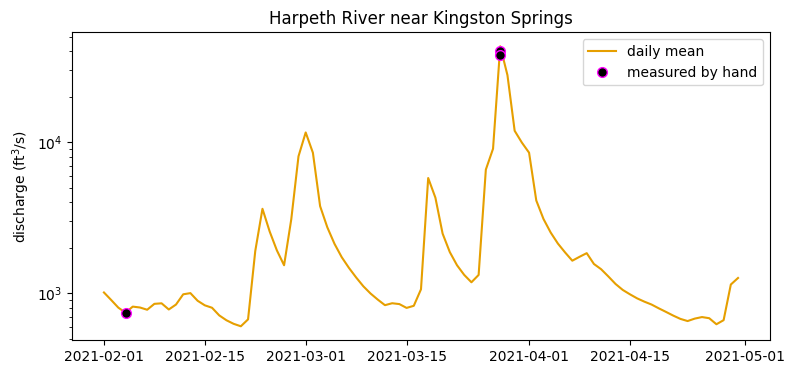

In [29]:
harpeth_days = everyday[everyday["short_name"] == "Harpeth"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(harpeth_days["time"], harpeth_days["value_daily"], color=colors["Harpeth"], label="daily mean")
ax.plot(harpeth_days["time"], harpeth_days["value_measured"], "o", color="black", markeredgecolor='magenta', markersize=7, label="measured by hand")

ax.set_yscale("log")
ax.set_ylabel("discharge (ft$^3$/s)")
ax.set_title("Harpeth River near Kingston Springs")
ax.legend();

#### What just happened?
The line is every day's mean. The black dots are the field visits: one quiet day in early February, and March 28, when the crew went out **during** the flood peak and measured twice, about an hour apart.

<div class="alert alert-info">

### Exercise 2 : what does a daily mean hide?

Use `compare` (the inner join).

1. Make a column `difference`: the measured value **minus** the daily mean.
2. Use a mask to keep only the rows where the measurement was **higher** than the daily mean.
3. Then run the figure cell below to look at Mill Creek around March 31.
    
</div>

In [30]:
compare["difference"] = compare["value_measured"] - compare["value_daily"]

higher = compare["difference"] > 0

compare[higher][["short_name", "time", "value_measured", "value_daily", "difference"]]

,short_name,time,value_measured,value_daily,difference
1,Cumberland,2021-02-08,12800,10700.0,2100.0
5,Mill Creek,2021-03-31,5440,2610.0,2830.0
6,Mill Creek,2021-03-31,4680,2610.0,2070.0
7,Mill Creek,2021-02-25,211,203.0,8.0


Once you have that correct, create this figure:

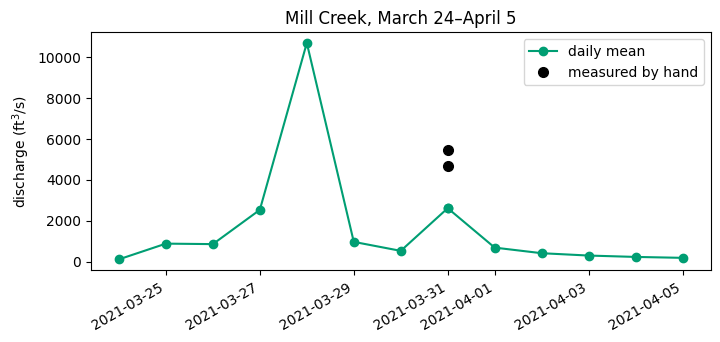

In [31]:
mill_days = everyday[everyday["short_name"] == "Mill Creek"]

after_start = mill_days["time"] >= "2021-03-24"
before_end = mill_days["time"] <= "2021-04-05"
in_window = after_start & before_end

mill_flood = mill_days[in_window]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(mill_flood["time"], mill_flood["value_daily"], "o-", color=colors["Mill Creek"], label="daily mean")
ax.plot(mill_flood["time"], mill_flood["value_measured"], "o", color="black", markersize=7, label="measured by hand")

ax.set_ylabel("discharge (ft$^3$/s)")
ax.set_title("Mill Creek, March 24–April 5")
ax.legend()
fig.autofmt_xdate();

<div class="alert alert-warning">

### Question 5:
On March 31, the crew measured about **twice** the daily mean. How can one measurement be so much bigger than the average for the same day? Look at the daily means for March 30, March 31, and April 1.

</div>

> your answer here

<details>
<summary style="color:green;"><strong>Answer</strong></summary>

Mill Creek fell to 521 ft³/s on March 30, jumped to 2,610 on March 31, and was down to 680 by April 1: a second, short burst of high water. A **daily mean** averages all 24 hours, so a peak that lasted a few hours gets diluted by the quiet hours around it. The crew happened to be there during the burst.

Small creeks change faster than one number per day can show. That's why gauges also record every 15 minutes.

</details>

---
## Part 5 : date is just another key
#### Which river peaked first?
To compare gauges day by day, put them **side by side**: one row per date, one column per gauge. That's a merge with `time` as the key.

### Step 1 : one small table per gauge

Keep only that gauge's rows, keep only `time` and `value`, and rename `value` to the river's name:

In [32]:
cumberland = daily[daily["monitoring_location_id"] == "USGS-03431500"]
cumberland = cumberland[["time", "value"]]
cumberland = cumberland.rename(columns={"value":"cumberland"})

harpeth = daily[daily["monitoring_location_id"] == "USGS-03434500"]
harpeth = harpeth[["time", "value"]]
harpeth = harpeth.rename(columns={"value":"harpeth"})

harpeth.head(5)

,time,harpeth
178,2021-02-01,1010.0
179,2021-02-02,901.0
180,2021-02-03,801.0
181,2021-02-04,742.0
182,2021-02-05,814.0


### Step 2 : merge on the date

In [33]:
wide = pd.merge(cumberland, harpeth, on="time")

print(wide.shape)
wide.head(3)

(89, 3)


,time,cumberland,harpeth
0,2021-02-01,16900.0,1010.0
1,2021-02-02,14600.0,901.0
2,2021-02-03,14600.0,801.0


This is the same idea as in Part 2 : the same `pd.merge`. The only difference is the key: a **date** instead of a gauge ID. For each date in `cumberland`, pandas found the same date in `harpeth` and put the two discharges in one row. **Any column can be a key**, as long as the same value means the same thing in both tables.

### Step 3 : zoom in on the flood
Three small steps: one mask for the start, one for the end, and `&` to keep rows where **both** are `True`:

In [34]:
after_start = wide["time"] >= "2021-03-25"  # mask for after start
before_end = wide["time"] <= "2021-04-01"   # mask for before the end
in_window = after_start & before_end        # combine both masks

time_tracked = wide[in_window]              # apply mask
time_tracked

,time,cumberland,harpeth
52,2021-03-25,43100.0,1320.0
53,2021-03-26,49500.0,6580.0
54,2021-03-27,59600.0,9050.0
55,2021-03-28,115000.0,43200.0
56,2021-03-29,123000.0,27800.0
57,2021-03-30,107000.0,11900.0
58,2021-03-31,91000.0,9940.0
59,2021-04-01,88900.0,8520.0


Reading across a row now compares the two rivers on the same: the Harpeth jumped from 9,050 to 43,200 ft$^3$/s March 28, while the Cumberland didn't reach its peak until the 29th.

#### two rivers, one table
Because both rivers are in one table, one `x` column serves both lines:

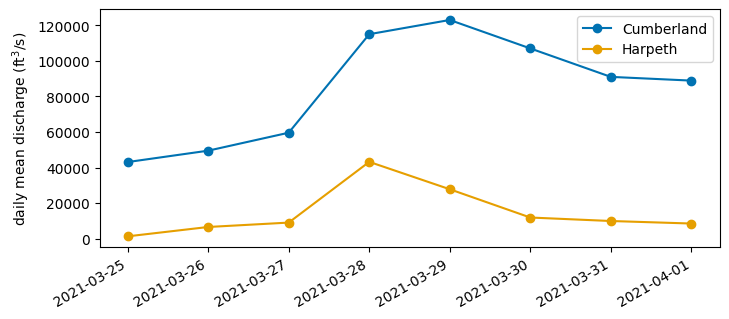

In [35]:
flood = wide[in_window]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(flood["time"], flood["cumberland"], "o-", color=colors["Cumberland"], label="Cumberland")
ax.plot(flood["time"], flood["harpeth"], "o-", color=colors["Harpeth"], label="Harpeth")

ax.set_ylabel("daily mean discharge (ft$^3$/s)")
ax.legend()
fig.autofmt_xdate();

<div class="alert alert-success">

**Tip**: a merge on dates only works if the dates really mean the same thing in both tables. Daily values are easy. With measurements every 15 minutes, two gauges' clocks rarely line up exactly, and a merge on time would match almost nothing. Then you first have to bin both onto the same time steps (Friday's lecture).
    
</div>

<div class="alert alert-info">

### Exercise 3 : who peaked first?

**Part A.**

Add Mill Creek to `wide` as a third column, `mill_creek`.
</div>

In [36]:
# your code here
mill_creek = daily[daily["short_name"] == "Mill Creek"]
mill_creek = mill_creek[["time", "value"]]
mill_creek = mill_creek.rename(columns={"value": "mill_creek"})

wide = pd.merge(wide, mill_creek, on="time")

wide.head(3)

,time,cumberland,harpeth,mill_creek
0,2021-02-01,16900.0,1010.0,114.0
1,2021-02-02,14600.0,901.0,98.4
2,2021-02-03,14600.0,801.0,87.1


<div class="alert alert-info">


**Part B.**

Find the **date** of each river's peak. The loop does all three rivers: for each one, keep the row where that column equals its own maximum.

</div>

In [37]:
for river in ["mill_creek", "harpeth", "cumberland"]:
    is_peak = wide[river] == wide[river].max()
    print(wide[is_peak][["time", river]])

         time  mill_creek
55 2021-03-28     10700.0
         time  harpeth
55 2021-03-28  43200.0
         time  cumberland
56 2021-03-29    123000.0


<div class="alert alert-info">


**Part C.**

Plot all three rivers as discharge **per square mile**, so a small creek and a big river can be compared fairly. The drainage areas from `gauges` are typed into a dictionary for you.
</div>

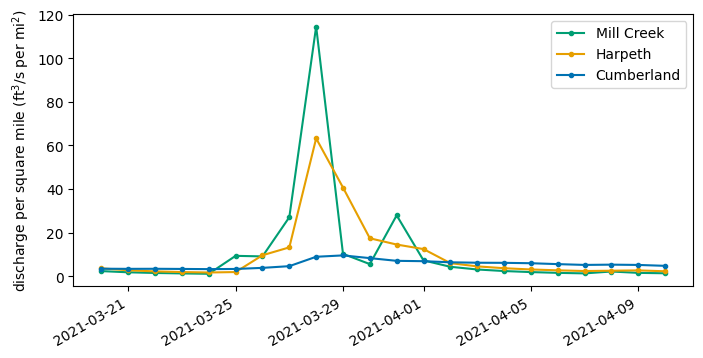

In [38]:
areas = {"mill_creek": 93.4, "harpeth": 683, "cumberland": 12856}
labels = {"mill_creek": "Mill Creek", "harpeth": "Harpeth", "cumberland": "Cumberland"}

after_start = wide["time"] >= "2021-03-20"
before_end = wide["time"] <= "2021-04-10"
in_window = after_start & before_end
flood = wide[in_window]

fig, ax = plt.subplots(figsize=(8, 4))
for river in ["mill_creek", "harpeth", "cumberland"]:
    per_sqmi = flood[river] / areas[river]
    name = labels[river]
    ax.plot(flood["time"], per_sqmi, "o-", markersize=3, label=name, color=colors[name])

ax.set_ylabel("discharge per square mile (ft$^3$/s per mi$^2$)")
ax.legend()
fig.autofmt_xdate();

---
## Part 6 : where did these files come from? (demo)

<div class="alert alert-success">

**Tip:** **Demo:** watch this part. You don't need to run it, and you won't be asked to write it.

</div>
You can download any of these files from **waterdata.usgs.gov**: search for a site, choose the data and dates, and download. That's fine for three gauges. For thirty, or for data you'll update every week, you can ask the USGS for data **from Python** instead. The USGS's own package, `dataretrieval`, sends the request and hands back a DataFrame:

In [39]:
RUN_DOWNLOAD = True      # I'll sets this to True in class

if RUN_DOWNLOAD:
    from dataretrieval import waterdata

    new_daily, metadata = waterdata.get_daily(
        monitoring_location_id="USGS-03431060",     # Mill Creek
        parameter_code="00060",                      # discharge
        statistic_id="00003",                        # daily mean
        time="2021-03-20/2021-04-10",
    )
    print(new_daily[["monitoring_location_id", "time", "value"]].head())

Retrieving: daily · 1 page · 22 rows


  monitoring_location_id       time  value
0          USGS-03431060 2021-03-20  221.0
1          USGS-03431060 2021-03-21  170.0
2          USGS-03431060 2021-03-22  141.0
3          USGS-03431060 2021-03-23  122.0
4          USGS-03431060 2021-03-24  106.0


Every number in that request is a code: `00060` means **discharge**, and `00003` means **daily mean**. USGS has hundreds of parameter codes, for things like water temperature, gauge height, and nitrate. A download script like this is also a record of **exactly** what you downloaded, which helps make your work reproducible.

Two things to know if you try it for your final project:
- Records aren't always complete online. The Cumberland's daily record goes back to 1892, but the new USGS system currently serves only values from October 2010 onward for that gauge.
- Check what you got back (`len()`, `.head()`, a quick plot) before you build anything on it.

---
## A useful table

|**you want**|**write**|
|:--|:--|
|join two tables on a key column|`pd.merge(left, right, on="KEY")`|
|join on two keys at once|`pd.merge(left, right, on=["KEY1", "KEY2"])`|
|key columns with different names|`pd.merge(left, right, left_on="A", right_on="B")`|
|choose your own endings for same-named columns|`suffixes=("_left", "_right")`|
|keep unmatched rows|`how="left"`, `"right"`, or `"outer"` (default `"inner"`)|
|see which rows matched|`indicator=True`, then `df["_merge"].value_counts()`|
|check that keys are what you expect|`validate="one_to_one"` or `"many_to_one"`|
|read an ID column as text (keep leading zeros)|`pd.read_csv(path, dtype={"ID": str})`|
|move a groupby index back into a column|`.reset_index()`|
|sort by two columns|`df.sort_values(["A", "B"])`|
|a log-scale axis|`ax.set_yscale("log")`|

**Check after every merge:** compare `.shape` before and after. Fewer rows than you expected means keys didn't match. More rows means a key was repeated.